# BB84 Quantum Cryptography

A simulation of BB84 (Bennett and Brassard, 1984), the first quantum cryptography protocol. Alice sends single qubits to Bob to build a shared secret key. An eavesdropper can't measure them without introducing errors, so she gets caught.

In [ ]:
!pip install -q qiskit qiskit-aer matplotlib

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator

sim = AerSimulator()
rng = np.random.default_rng()

### The circuit

Alice encodes a bit in one of two bases. In Z, 0 is ket(0) and 1 is ket(1). In X, 0 is ket(+) and 1 is ket(-). 

Bob measures in a basis he picks at random. Basis 0 = Z, basis 1 = X.

If Eve is listening, she measures in her own random basis first and sends on what she saw.

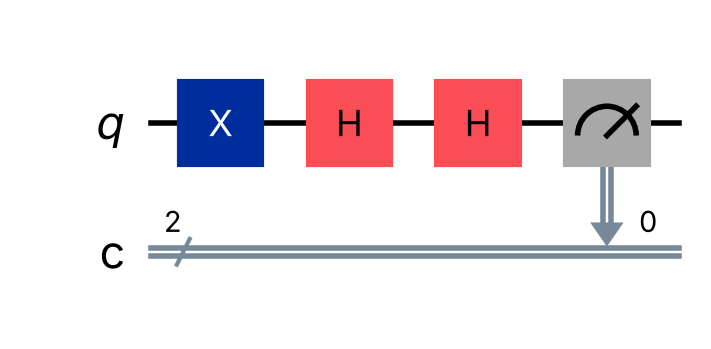

In [3]:
def send_qubit(bit, alice_basis, bob_basis, eve_basis=None):
    qc = QuantumCircuit(1, 2)
    if bit == 1:
        qc.x(0)
    if alice_basis == 1:
        qc.h(0)

    if eve_basis is not None:
        if eve_basis == 1:
            qc.h(0)
        qc.measure(0, 1)
        if eve_basis == 1:
            qc.h(0)

    if bob_basis == 1:
        qc.h(0)
    qc.measure(0, 0)
    return qc

send_qubit(1, 1, 1).draw("mpl")

### Running the rounds
Rounds with the same choices are run together to keep it fast.

In [4]:
def run_rounds(n_rounds, eve=False):
    alice_bits = rng.integers(0, 2, n_rounds)
    alice_bases = rng.integers(0, 2, n_rounds)
    bob_bases = rng.integers(0, 2, n_rounds)
    eve_bases = rng.integers(0, 2, n_rounds) if eve else np.full(n_rounds, -1)

    bob_bits = np.zeros(n_rounds, dtype=int)

    for bit, a, b, e in set(zip(alice_bits, alice_bases, bob_bases, eve_bases)):
        these = (alice_bits == bit) & (alice_bases == a) & (bob_bases == b) & (eve_bases == e)
        qc = transpile(send_qubit(bit, a, b, e if e >= 0 else None), sim)
        memory = sim.run(qc, shots=int(these.sum()), memory=True).result().get_memory()
        bob_bits[these] = [int(m[-1]) for m in memory]

    return alice_bits, alice_bases, bob_bases, bob_bits

rounds = 4000
safe = run_rounds(rounds)

### The key
Alice and Bob publicly compare bases, but never bits. They keep the rounds where the bases matched, about half of them.

In [ ]:
def make_key(alice_bits, alice_bases, bob_bases, bob_bits):
    same_basis = alice_bases == bob_bases
    return alice_bits[same_basis], bob_bits[same_basis]

def show_key(alice_key, bob_key, n=40):
    a = "".join(map(str, alice_key[:n]))
    b = "".join(map(str, bob_key[:n]))
    marks = "".join(" " if x == y else "^" for x, y in zip(a, b))
    print(f"alice's key: {a}")
    print(f"bob's key:   {b}")
    print(f"mismatches:  {marks}")
    print(f"key length: {len(alice_key)} bits")

safe_alice, safe_bob = make_key(*safe)
show_key(safe_alice, safe_bob)

alice's key: 1100110001000110001000001011010000011001
bob's key:   1100110001000110001000001011010000011001
mismatches:                                          
key length: 1984 bits


### The check
They reveal a random sample of their key bits and compare them. The sample is then discarded, since it's now public. If more than about 11% mismatch, they abort.

In [6]:
def check_sample(alice_key, bob_key, fraction=0.25):
    sample = rng.random(len(alice_key)) < fraction
    error_rate = np.mean(alice_key[sample] != bob_key[sample])
    final_key = alice_key[~sample]
    verdict = "abort" if error_rate > 0.11 else "keep"
    print(f"sample size: {sample.sum()} bits, error rate: {error_rate:.1%}, verdict: {verdict}")
    print(f"final key: {len(final_key)} bits")
    return error_rate

safe_error = check_sample(safe_alice, safe_bob)

sample size: 472 bits, error rate: 0.0%, verdict: keep
final key: 1512 bits


### Adding Eve
Eve measures every qubit in a random basis and sends on what she saw. When her basis is wrong, she changes the qubit, and Bob gets a random result.

In [7]:
spied = run_rounds(rounds, eve=True)

spied_alice, spied_bob = make_key(*spied)
show_key(spied_alice, spied_bob)
spied_error = check_sample(spied_alice, spied_bob)

alice's key: 0001001100101111111101011101010110001010
bob's key:   1010011100101101110101111101011000110010
mismatches:  ^ ^^ ^        ^   ^   ^       ^^^ ^^^   
key length: 1990 bits
sample size: 506 bits, error rate: 26.9%, verdict: abort
final key: 1484 bits


Eve guesses the wrong basis half the time, and each wrong guess gives Bob a wrong bit half the time, so about 25% of the key is wrong. Well above 11%, so Alice and Bob abort.

### Comparison

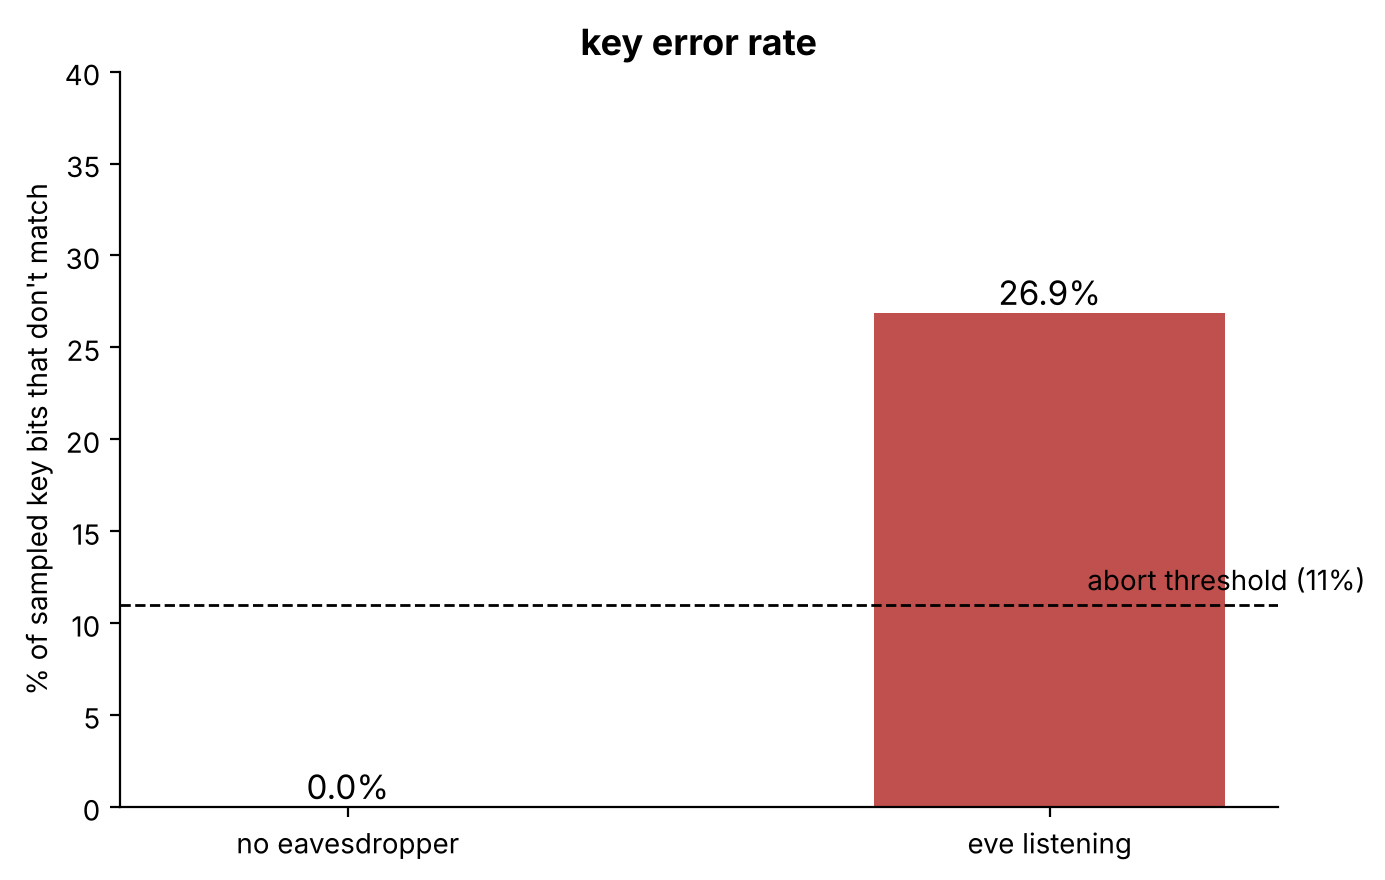

In [8]:
fig, ax = plt.subplots(figsize=(7, 4.5))
labels = ["no eavesdropper", "eve listening"]
bars = ax.bar(labels, [safe_error * 100, spied_error * 100], color=["#3b6ea8", "#c0504d"], width=0.5)
ax.bar_label(bars, fmt="%.1f%%", fontsize=12)
ax.axhline(11, color="black", linestyle="--", linewidth=1)
ax.text(1.45, 11.8, "abort threshold (11%)", ha="right", fontsize=10)
ax.set_ylim(0, 40)
ax.set_ylabel("% of sampled key bits that don't match")
ax.set_title("key error rate", fontsize=13, fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

### Notes
- BB84 secures how the key is shared. Messages are then encrypted normally with that key.
- Real systems send single photons over noisy channels, so some errors happen even without Eve. That's why the threshold is around 11%, not 0%.
- This is a simplified simulation for learning.